# PS6: Facial Emotion Recognition using a CNN (CK+)
7 emotions: anger, contempt, disgust, fear, happy, sadness, surprise (48x48 grayscale).

In [12]:
import pathlib
import re
import subprocess
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf
from sklearn.metrics import classification_report, confusion_matrix, f1_score
from sklearn.model_selection import train_test_split
from sklearn.utils.class_weight import compute_class_weight
from tensorflow import keras
from tensorflow.keras import layers

DATA_DIR = None
KAGGLE_DATASET = 'shawon10/ckplus'
IMG = (48, 48)
BATCH = 32
EPOCHS = 80
SEED = 42
keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
print('TensorFlow:', tf.__version__)
if gpus:
    print('GPU:', gpus[0].name)
    try:
        out = subprocess.check_output(
            ['nvidia-smi', '--query-gpu=memory.free,memory.total', '--format=csv,noheader,nounits'],
            text=True, stderr=subprocess.DEVNULL)
        free_mb, total_mb = [int(v) for v in out.strip().splitlines()[0].split(',')]
        print(f'VRAM: {total_mb} MB total, {free_mb} MB free')
    except Exception:
        print('VRAM: could not query nvidia-smi')
else:
    print('No GPU found. CK+ is small, so CPU training also works (just slower).')

TensorFlow: 2.21.0
No GPU found. CK+ is small, so CPU training also works (just slower).


In [13]:
if DATA_DIR is None:
    try:
        import kagglehub
        DATA_DIR = kagglehub.dataset_download(KAGGLE_DATASET)
    except Exception as exc:
        print('=' * 66)
        print('DATASET DOWNLOAD FAILED')
        print('Option 1: add a Kaggle API token (Colab Secrets: KAGGLE_API_TOKEN).')
        print('Option 2: set DATA_DIR in Cell 1 to a local CK+48 folder.')
        print('Expected layout: DATA_DIR/<emotion>/*.png with 7 emotion folders.')
        print('=' * 66)
        raise SystemExit('Stopped: dataset not available.') from exc

root = pathlib.Path(DATA_DIR)
matches = [p.parent for p in root.rglob('surprise') if p.is_dir()]
DATA_ROOT = matches[0] if matches else root
class_dirs = sorted([d for d in DATA_ROOT.iterdir() if d.is_dir()])
class_names = [d.name for d in class_dirs]
num_classes = len(class_names)

paths, labels = [], []
for idx, d in enumerate(class_dirs):
    files = sorted(list(d.glob('*.png')) + list(d.glob('*.jpg')) + list(d.glob('*.jpeg')))
    paths.extend(str(f) for f in files)
    labels.extend([idx] * len(files))
paths = np.array(paths)
labels = np.array(labels)
print('Data root:', DATA_ROOT)
print('Emotion folders:', class_names)
print('Total images:', len(paths))

Data root: C:\Users\DELL\.cache\kagglehub\datasets\shawon10\ckplus\versions\1\CK+48
Emotion folders: ['anger', 'contempt', 'disgust', 'fear', 'happy', 'sadness', 'surprise']
Total images: 981


In [14]:
pattern = re.compile(r'[Ss]\d{3}')
subjects = []
for p in paths:
    m = pattern.search(pathlib.Path(p).stem)
    subjects.append(m.group(0).upper() if m else None)
subjects = np.array(subjects, dtype=object)
subject_split = all(s is not None for s in subjects)

if subject_split:
    unique = np.array(sorted(set(subjects)))
    np.random.default_rng(SEED).shuffle(unique)
    n = len(unique)
    n_tr = int(0.7 * n)
    n_va = int(0.15 * n)
    groups = {'train': set(unique[:n_tr]),
              'val': set(unique[n_tr:n_tr + n_va]),
              'test': set(unique[n_tr + n_va:])}
    masks = {k: np.array([s in v for s in subjects]) for k, v in groups.items()}
    print(f'Split mode: SUBJECT-INDEPENDENT ({n} subjects -> {n_tr}/{n_va}/{n - n_tr - n_va})')
else:
    idx = np.arange(len(paths))
    i_tr, i_tmp = train_test_split(idx, test_size=0.3, stratify=labels, random_state=SEED)
    i_va, i_te = train_test_split(i_tmp, test_size=0.5, stratify=labels[i_tmp], random_state=SEED)
    masks = {'train': np.isin(idx, i_tr), 'val': np.isin(idx, i_va), 'test': np.isin(idx, i_te)}
    print('Split mode: STRATIFIED RANDOM (no subject IDs found in filenames)')
    print('Warning: frames of the same person may appear in several splits, so scores are optimistic.')

for k in ['train', 'val', 'test']:
    print(k, int(masks[k].sum()))

Split mode: SUBJECT-INDEPENDENT (118 subjects -> 82/17/19)
train 696
val 120
test 165


In [15]:
AUTOTUNE = tf.data.AUTOTUNE


def load_image(path, label):
    img = tf.io.read_file(path)
    img = tf.io.decode_image(img, channels=1, expand_animations=False)
    img = tf.image.resize(img, IMG)
    return tf.cast(img, tf.float32), label


def make_ds(mask, training):
    ds = tf.data.Dataset.from_tensor_slices((paths[mask], labels[mask]))
    ds = ds.map(load_image, num_parallel_calls=AUTOTUNE)
    ds = ds.cache()
    if training:
        ds = ds.shuffle(1024, seed=SEED)
    return ds.batch(BATCH).prefetch(AUTOTUNE)


train_ds = make_ds(masks['train'], True)
val_ds = make_ds(masks['val'], False)
test_ds = make_ds(masks['test'], False)
y_train = labels[masks['train']]
weights = compute_class_weight('balanced', classes=np.arange(num_classes), y=y_train)
class_weight = dict(enumerate(weights))
print('Class weights:', {class_names[k]: round(float(v), 2) for k, v in class_weight.items()})

Class weights: {'anger': 0.97, 'contempt': 2.76, 'disgust': 0.79, 'fear': 1.66, 'happy': 0.74, 'sadness': 1.51, 'surprise': 0.58}


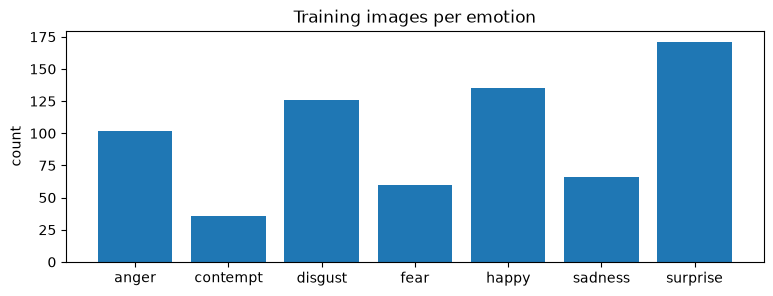

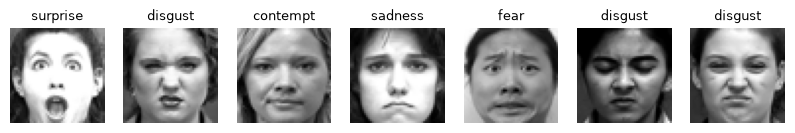

In [16]:
counts = np.bincount(y_train, minlength=num_classes)
plt.figure(figsize=(9, 3))
plt.bar(class_names, counts)
plt.title('Training images per emotion')
plt.ylabel('count')
plt.show()

plt.figure(figsize=(10, 3))
for images, lab in train_ds.take(1):
    for i in range(7):
        plt.subplot(1, 7, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        plt.title(class_names[lab[i]], fontsize=9)
        plt.axis('off')
plt.show()

## Model

In [17]:
model = keras.Sequential([
    layers.Input(IMG + (1,)),
    layers.Rescaling(1.0 / 255),
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.08),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.05, 0.05),
    layers.Conv2D(32, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(128, 3, padding='same', use_bias=False),
    layers.BatchNormalization(),
    layers.Activation('relu'),
    layers.MaxPooling2D(),
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.4),
    layers.Dense(num_classes, activation='softmax'),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3),
              loss='sparse_categorical_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)              │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_flip_1 (RandomFlip)           │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_rotation_1 (RandomRotation)   │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_zoom_1 (RandomZoom)           │ (None, 48, 48, 1)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ random_translation_1                 │ (None, 48, 48, 1)           │               0 │
│ (RandomTranslation)                  │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 48, 48, 32)          │             288 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 48, 48, 32)          │             128 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_3 (Activation)            │ (None, 48, 48, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 24, 24, 32)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 24, 24, 64)          │          18,432 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 24, 24, 64)          │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_4 (Activation)            │ (None, 24, 24, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_4 (MaxPooling2D)       │ (None, 12, 12, 64)          │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 12, 12, 128)         │          73,728 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_5                │ (None, 12, 12, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ activation_5 (Activation)            │ (None, 12, 12, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_5 (MaxPooling2D)       │ (None, 6, 6, 128)           │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d_1           │ (None, 128)                 │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 128)                 │              

 Total params: 94,247 (368.15 KB)

 Trainable params: 93,799 (366.40 KB)

 Non-trainable params: 448 (1.75 KB)

## Training

In [18]:
callbacks = [
    keras.callbacks.ModelCheckpoint('best_ckplus_cnn.keras', monitor='val_accuracy', save_best_only=True),
    keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=6, min_lr=1e-6, verbose=1),
    keras.callbacks.EarlyStopping(monitor='val_loss', patience=15, restore_best_weights=True),
]
history = model.fit(
    train_ds, validation_data=val_ds, epochs=EPOCHS,
    class_weight=class_weight, callbacks=callbacks, verbose=2)

Epoch 1/10


C:\Users\DELL\AppData\Local\Programs\Python\Python312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


22/22 - 4s - 190ms/step - accuracy: 0.2227 - loss: 2.2104 - val_accuracy: 0.1000 - val_loss: 2.0189 - learning_rate: 0.0010
Epoch 2/10
22/22 - 1s - 59ms/step - accuracy: 0.2299 - loss: 1.9728 - val_accuracy: 0.1000 - val_loss: 2.3124 - learning_rate: 0.0010
Epoch 3/10
22/22 - 1s - 58ms/step - accuracy: 0.2371 - loss: 1.8273 - val_accuracy: 0.1000 - val_loss: 2.7336 - learning_rate: 0.0010
Epoch 4/10
22/22 - 1s - 59ms/step - accuracy: 0.2773 - loss: 1.8150 - val_accuracy: 0.1000 - val_loss: 3.0946 - learning_rate: 0.0010
Epoch 5/10
22/22 - 1s - 58ms/step - accuracy: 0.3017 - loss: 1.7678 - val_accuracy: 0.1000 - val_loss: 3.4146 - learning_rate: 0.0010
Epoch 6/10
22/22 - 1s - 58ms/step - accuracy: 0.2859 - loss: 1.7512 - val_accuracy: 0.1000 - val_loss: 3.9140 - learning_rate: 0.0010
Epoch 7/10

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
22/22 - 1s - 58ms/step - accuracy: 0.3032 - loss: 1.6731 - val_accuracy: 0.1000 - val_loss: 4.2745 - learning_rate: 0.

## Evaluation

Test accuracy: 0.0364   Test loss: 1.9937


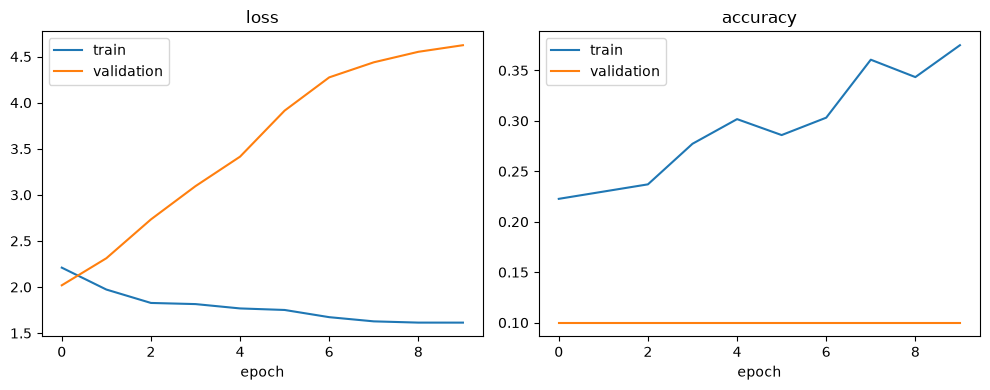

In [19]:
loss, acc = model.evaluate(test_ds, verbose=0)
print(f'Test accuracy: {acc:.4f}   Test loss: {loss:.4f}')

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for i, metric in enumerate(['loss', 'accuracy']):
    ax[i].plot(history.history[metric], label='train')
    ax[i].plot(history.history['val_' + metric], label='validation')
    ax[i].set_title(metric)
    ax[i].set_xlabel('epoch')
    ax[i].legend()
plt.tight_layout()
plt.show()

              precision    recall  f1-score   support

       anger     0.0000    0.0000    0.0000        24
    contempt     0.0364    1.0000    0.0702         6
     disgust     0.0000    0.0000    0.0000        33
        fear     0.0000    0.0000    0.0000         3
       happy     0.0000    0.0000    0.0000        42
     sadness     0.0000    0.0000    0.0000        12
    surprise     0.0000    0.0000    0.0000        45

    accuracy                         0.0364       165
   macro avg     0.0052    0.1429    0.0100       165
weighted avg     0.0013    0.0364    0.0026       165

Macro F1: 0.0100


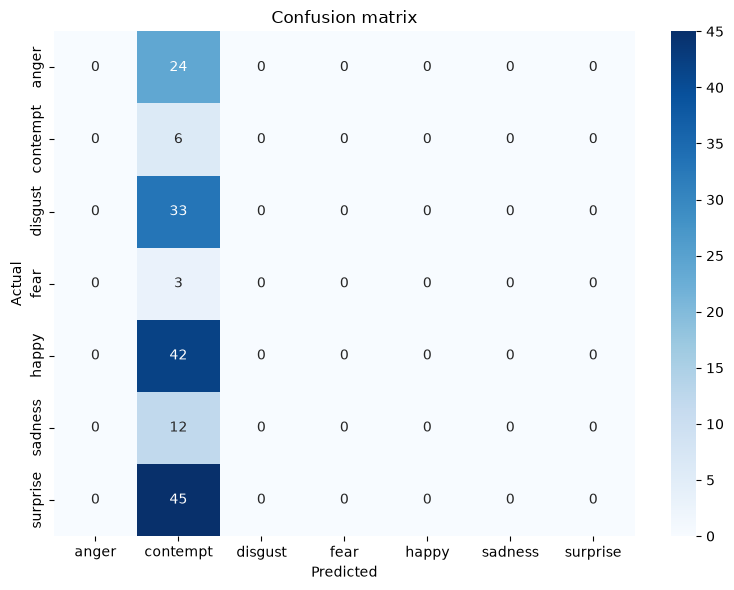

In [20]:
y_true = np.concatenate([lab.numpy() for _, lab in test_ds])
y_pred = model.predict(test_ds, verbose=0).argmax(axis=1)
print(classification_report(y_true, y_pred, labels=range(num_classes),
                            target_names=class_names, digits=4, zero_division=0))
print(f'Macro F1: {f1_score(y_true, y_pred, average="macro", zero_division=0):.4f}')

plt.figure(figsize=(8, 6))
sns.heatmap(confusion_matrix(y_true, y_pred, labels=range(num_classes)),
            annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion matrix')
plt.tight_layout()
plt.show()

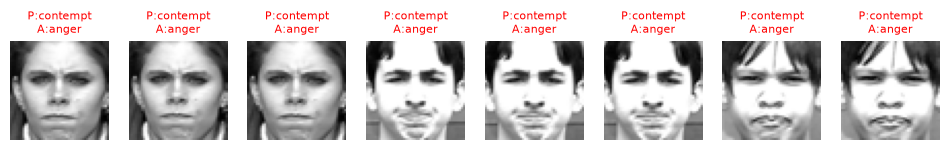

In [21]:
plt.figure(figsize=(12, 3))
for images, lab in test_ds.take(1):
    probs = model.predict(images[:8], verbose=0)
    for i in range(8):
        plt.subplot(1, 8, i + 1)
        plt.imshow(images[i].numpy().squeeze(), cmap='gray')
        p, t = int(probs[i].argmax()), int(lab[i])
        plt.title(f'P:{class_names[p]}\nA:{class_names[t]}', fontsize=8,
                  color='green' if p == t else 'red')
        plt.axis('off')
plt.show()

## Save and single-image inference

In [22]:
model.save('ckplus_cnn_final.keras')
print('Saved: best_ckplus_cnn.keras and ckplus_cnn_final.keras')


def predict_image(path):
    img = keras.utils.load_img(path, color_mode='grayscale', target_size=IMG)
    x = keras.utils.img_to_array(img)[None, ...]
    probs = model.predict(x, verbose=0)[0]
    plt.imshow(img, cmap='gray')
    plt.axis('off')
    plt.title(f'{class_names[probs.argmax()]} ({probs.max():.1%})')
    plt.show()
    return dict(zip(class_names, probs.round(4)))

Saved: best_ckplus_cnn.keras and ckplus_cnn_final.keras
